# CSE 848: Generative AI & Applications
## Activity 1: Exploring MLP and CNN Performance on CIFAR-10

**Student name:** Malik Saif Ullah
**Registration number:** `538668`

---
**Runtime tip:** use a GPU (`Runtime > Change runtime type > T4 GPU`) and then `Runtime > Run all`. On a T4 the whole notebook takes roughly 5 to 10 minutes. Every table, plot, observation and the final discussion below is generated from the actual runs, so nothing needs to be typed in by hand except the registration number above.

## 0. Plan

| Item | Choice |
|---|---|
| Dataset | CIFAR-10, 32 x 32 RGB, 10 classes. 45,000 train / 5,000 validation (random split of the official train set) / 10,000 test (official test set) |
| Baseline MLP | Flatten, Linear 3072 to 512, ReLU, Linear 512 to 256, ReLU, Linear 256 to 10 |
| Baseline CNN | Conv 3 to 32, ReLU, MaxPool, Conv 32 to 64, ReLU, MaxPool, Linear 4096 to 128, ReLU, Linear 128 to 10 |
| Fixed settings (all runs) | Adam, batch size 64, 10 epochs, no data augmentation, per channel normalisation, seed 42, same data split |
| Baseline values | Learning rate 0.001, dropout 0 |
| **Two parameters tested** | **Learning rate** (0.01, 0.001, 0.0001) and **Dropout** (0, 0.25, 0.5) |
| Protocol | Change one parameter at a time, everything else fixed, applied to **both** models |
| Total runs | 2 baselines + 4 MLP experiments + 4 CNN experiments = **10 configurations** (the task asks for at least 3) |

**Why these two parameters?** They attack two different failure modes. Learning rate controls *optimisation* (can the model even fit the training data, and how quickly?). Dropout controls *generalisation* (does the model memorise the training set?). Testing one parameter of each kind lets the discussion separate underfitting caused by bad optimisation from overfitting caused by excess capacity, which is exactly what the assignment asks us to reason about. Running the same sweeps on both models also shows whether the *architecture* changes how sensitive a model is to the hyperparameter.

## 1. Setup and data

In [1]:
import copy, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| PyTorch", torch.__version__)
if device.type == "cpu":
    print("WARNING: running on CPU will be slow. Switch the Colab runtime to GPU.")

Device: cuda | PyTorch 2.11.0+cu130


In [2]:
# Download CIFAR-10 and move everything to the device once (the dataset is small),
# so training loops do not pay any data-loader overhead.
train_raw = torchvision.datasets.CIFAR10(root="./data", train=True,  download=True)
test_raw  = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)
CLASSES = train_raw.classes

mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1)

def to_tensors(ds):
    x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).float() / 255.0
    x = (x - mean) / std
    return x.to(device), torch.tensor(ds.targets).to(device)

X_all, y_all = to_tensors(train_raw)
X_test, y_test = to_tensors(test_raw)

# Fixed 45k / 5k train / validation split (same split for every experiment)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g).to(device)
X_train, y_train = X_all[perm[:45000]], y_all[perm[:45000]]
X_val,   y_val   = X_all[perm[45000:]], y_all[perm[45000:]]
del X_all, y_all
if device.type == "cuda":
    torch.cuda.empty_cache()

print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))
print("classes:", CLASSES)

100%|██████████| 170M/170M [1:03:38<00:00, 44.6kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32)
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


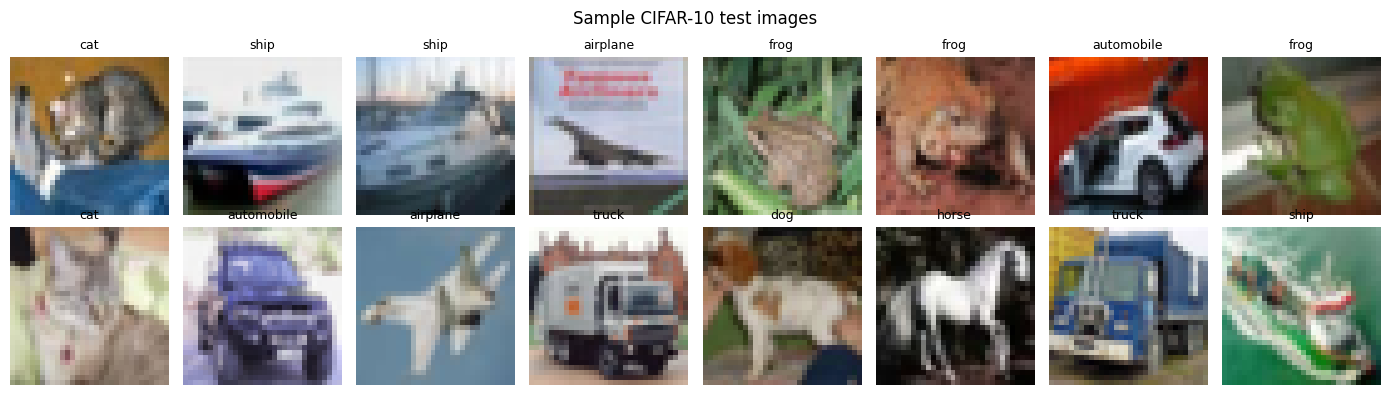

In [3]:
# Quick look at the data
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(test_raw.data[i]); ax.set_title(CLASSES[test_raw.targets[i]], fontsize=9); ax.axis("off")
plt.suptitle("Sample CIFAR-10 test images"); plt.tight_layout(); plt.show()

## 2. Models

Both models are deliberately small and standard, so that differences in the results can be attributed to the *architecture* and the *hyperparameter*, not to tricks (no batch norm, no residual connections, no augmentation).

* **MLP** treats the image as a flat vector of 3072 numbers. It has no notion that neighbouring pixels are related, so every pixel gets its own weight to every hidden unit.
* **CNN** uses small 3 x 3 filters that slide across the image (weight sharing) and max pooling (partial translation invariance). This builds in the assumption that useful features are local and can appear anywhere.

In [4]:
class MLP(nn.Module):
    def __init__(self, hidden=(512, 256), dropout=0.0):
        super().__init__()
        layers, d = [nn.Flatten()], 3 * 32 * 32
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 10))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

class CNN(nn.Module):
    def __init__(self, filters=(32, 64), fc=128, dropout=0.0):
        super().__init__()
        f1, f2 = filters
        self.features = nn.Sequential(
            nn.Conv2d(3, f1, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32x32 -> 16x16
            nn.Conv2d(f1, f2, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 16x16 -> 8x8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(f2 * 8 * 8, fc), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(fc, 10),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def build(model_type, dropout):
    return MLP(dropout=dropout) if model_type == "MLP" else CNN(dropout=dropout)

print("MLP:", MLP(), f"\nTrainable parameters: {count_params(MLP()):,}\n")
print("CNN:", CNN(), f"\nTrainable parameters: {count_params(CNN()):,}")

MLP: MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.0, inplace=False)
    (7): Linear(in_features=256, out_features=10, bias=True)
  )
) 
Trainable parameters: 1,707,274

CNN: CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linea

## 3. Training and evaluation code

Design decisions worth knowing about (they affect how the numbers should be read):

1. **Train metrics are measured in eval mode** at the end of each epoch on the full training set. If we averaged the loss during the epoch instead, dropout would be switched on and the training accuracy would look artificially low, which would hide overfitting and make the train/validation gap misleading for dropout runs.
2. **Test accuracy is reported at the epoch with the best validation accuracy** (a simple form of early stopping). The test set is never used to pick that epoch.
3. **Every run restarts from the same seed**, so weight initialisation and batch order are identical across configurations. Any difference then comes from the one parameter that was changed.

In [5]:
EPOCHS, BATCH = 10, 64
BASE_LR, BASE_DROPOUT = 1e-3, 0.0

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss_sum += F.cross_entropy(out, y[i:i + bs], reduction="sum").item()
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss_sum / len(X), 100.0 * correct / len(X)

def run_experiment(model_type, lr, dropout, factor):
    set_seed()
    model = build(model_type, dropout).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best_val, best_state, best_epoch = -1.0, None, 0
    n, t0 = len(X_train), time.time()

    for ep in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(n, device=device)
        for i in range(0, n, BATCH):
            idx = order[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            loss.backward()
            opt.step()
        tl, ta = evaluate(model, X_train, y_train)
        vl, va = evaluate(model, X_val, y_val)
        for k, v in zip(hist, (tl, ta, vl, va)):
            hist[k].append(v)
        if va > best_val:
            best_val, best_epoch, best_state = va, ep, copy.deepcopy(model.state_dict())

    final_test_loss, final_test_acc = evaluate(model, X_test, y_test)   # last epoch weights
    model.load_state_dict(best_state)
    test_loss, test_acc = evaluate(model, X_test, y_test)               # best validation epoch
    label = f"{model_type}, LR={lr:g}, Dropout={dropout:g}"
    if factor == "Baseline":
        label += " (baseline)"
    res = dict(model=model_type, lr=lr, dropout=dropout, factor=factor, label=label,
               params=count_params(model), hist=hist, best_epoch=best_epoch,
               train_acc=hist["train_acc"][-1], val_acc=hist["val_acc"][-1],
               best_val_acc=best_val, test_acc=test_acc, test_loss=test_loss,
               final_test_acc=final_test_acc)
    print(f"{label:<42} params={res['params']:>9,} | train {res['train_acc']:5.1f}% "
          f"val {res['val_acc']:5.1f}% | TEST {test_acc:5.2f}% (best epoch {best_epoch}) "
          f"[{time.time() - t0:.0f}s]")
    return res

## 4. Part A: Baseline models

Learning rate 0.001, dropout 0, Adam, batch size 64, 10 epochs.

In [6]:
results = []
for m in ["MLP", "CNN"]:
    results.append(run_experiment(m, BASE_LR, BASE_DROPOUT, "Baseline"))

MLP, LR=0.001, Dropout=0 (baseline)        params=1,707,274 | train  71.2% val  51.7% | TEST 51.29% (best epoch 5) [12s]
CNN, LR=0.001, Dropout=0 (baseline)        params=  545,098 | train  94.7% val  71.2% | TEST 72.17% (best epoch 6) [23s]


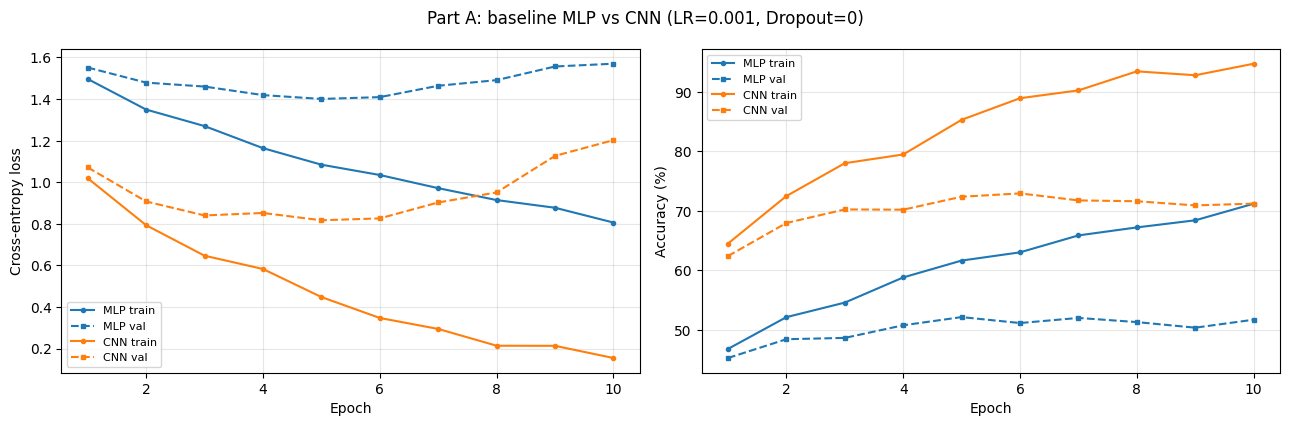

,Model,Final train loss,Final train acc (%),Final val acc (%),Test acc (%),Trainable parameters
0,MLP,0.8061,71.21,51.70,51.29,"1,707,274"
1,CNN,0.1546,94.74,71.22,72.17,"545,098"


In [8]:
def get(model, lr, dropout):
    for r in results:
        if r["model"] == model and r["lr"] == lr and r["dropout"] == dropout:
            return r

def plot_runs(named_runs, title):
    """Solid line = training, dashed line = validation. Left: loss, right: accuracy."""
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
    for i, (name, r) in enumerate(named_runs):
        c = plt.cm.tab10.colors[i % 10]
        ep = range(1, len(r["hist"]["train_loss"]) + 1)
        ax[0].plot(ep, r["hist"]["train_loss"], color=c, ls="-",  marker="o", ms=3, label=f"{name} train")
        ax[0].plot(ep, r["hist"]["val_loss"],   color=c, ls="--", marker="s", ms=3, label=f"{name} val")
        ax[1].plot(ep, r["hist"]["train_acc"],  color=c, ls="-",  marker="o", ms=3, label=f"{name} train")
        ax[1].plot(ep, r["hist"]["val_acc"],    color=c, ls="--", marker="s", ms=3, label=f"{name} val")
    ax[0].set_ylabel("Cross-entropy loss"); ax[1].set_ylabel("Accuracy (%)")
    for a in ax:
        a.set_xlabel("Epoch"); a.grid(alpha=0.3); a.legend(fontsize=8)
    fig.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

plot_runs([("MLP", get("MLP", BASE_LR, BASE_DROPOUT)), ("CNN", get("CNN", BASE_LR, BASE_DROPOUT))],
          "Part A: baseline MLP vs CNN (LR=0.001, Dropout=0)")

base_table = pd.DataFrame([{
    "Model": r["model"], "Final train loss": round(r["hist"]["train_loss"][-1], 4),
    "Final train acc (%)": round(r["train_acc"], 2), "Final val acc (%)": round(r["val_acc"], 2),
    "Test acc (%)": round(r["test_acc"], 2), "Trainable parameters": f"{r['params']:,}",
} for r in results])
display(base_table)

## 5. Part B: Experiments

**Parameter 1: Learning rate** (0.01, 0.001, 0.0001), dropout fixed at 0.
**Parameter 2: Dropout** (0, 0.25, 0.5), learning rate fixed at 0.001.

The baseline (LR 0.001, dropout 0) is the shared middle point of both sweeps, so each sweep needs only two new runs per model.

In [9]:
for m in ["MLP", "CNN"]:
    for lr in [0.01, 0.0001]:
        results.append(run_experiment(m, lr, BASE_DROPOUT, "Learning rate"))
    for dp in [0.25, 0.5]:
        results.append(run_experiment(m, BASE_LR, dp, "Dropout"))

MLP, LR=0.01, Dropout=0                    params=1,707,274 | train  19.8% val  18.3% | TEST 23.58% (best epoch 2) [12s]
MLP, LR=0.0001, Dropout=0                  params=1,707,274 | train  71.8% val  53.0% | TEST 53.75% (best epoch 9) [12s]
MLP, LR=0.001, Dropout=0.25                params=1,707,274 | train  58.7% val  49.9% | TEST 49.71% (best epoch 10) [12s]
MLP, LR=0.001, Dropout=0.5                 params=1,707,274 | train  47.4% val  44.4% | TEST 44.45% (best epoch 10) [12s]
CNN, LR=0.01, Dropout=0                    params=  545,098 | train  52.1% val  48.3% | TEST 47.48% (best epoch 10) [21s]
CNN, LR=0.0001, Dropout=0                  params=  545,098 | train  69.9% val  65.3% | TEST 65.44% (best epoch 9) [21s]
CNN, LR=0.001, Dropout=0.25                params=  545,098 | train  92.0% val  71.9% | TEST 72.02% (best epoch 6) [21s]
CNN, LR=0.001, Dropout=0.5                 params=  545,098 | train  85.5% val  72.7% | TEST 73.34% (best epoch 10) [21s]


### 5.1 Learning rate sweep: training and validation curves

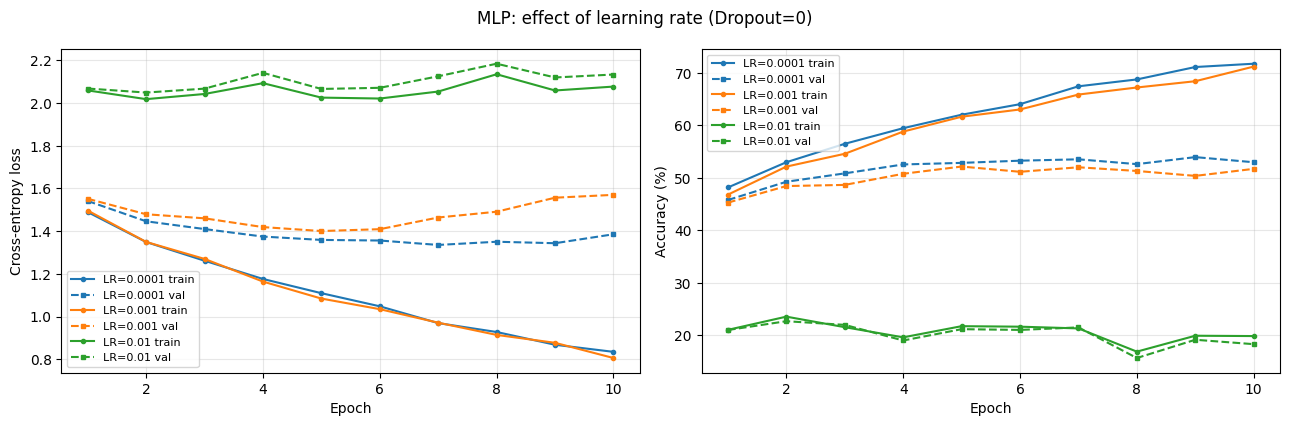

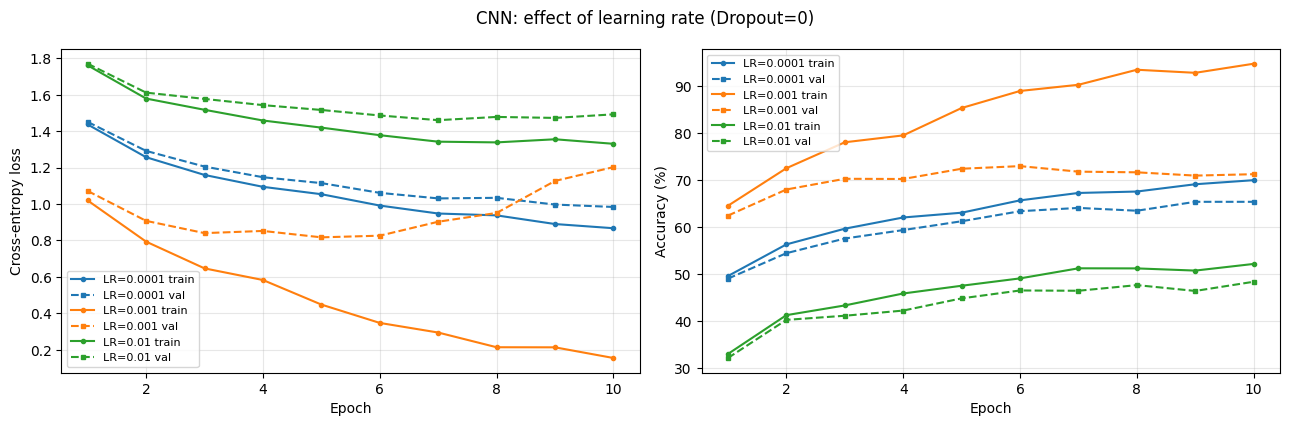

In [10]:
for m in ["MLP", "CNN"]:
    plot_runs([(f"LR={lr:g}", get(m, lr, BASE_DROPOUT)) for lr in [0.0001, 0.001, 0.01]],
              f"{m}: effect of learning rate (Dropout=0)")

### 5.2 Dropout sweep: training and validation curves

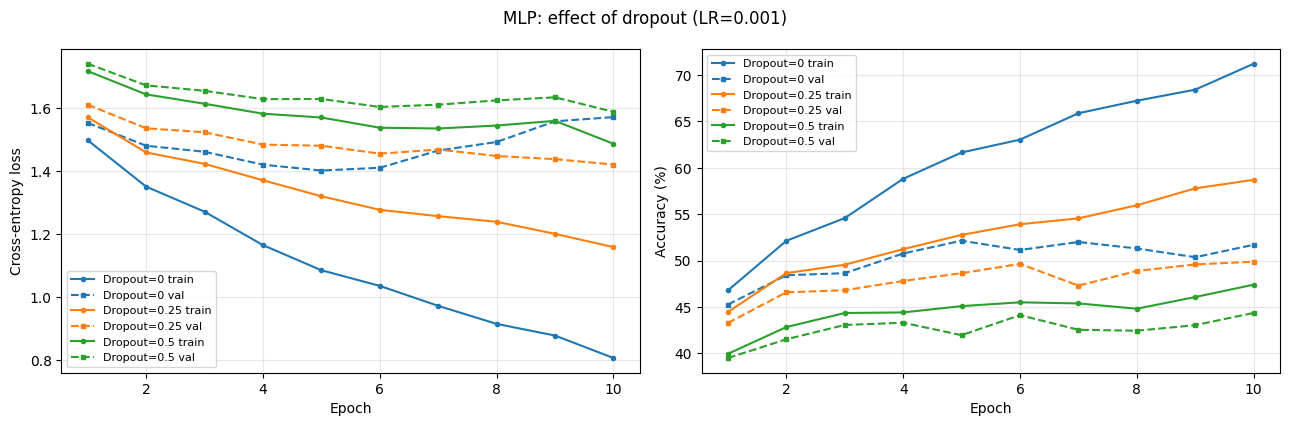

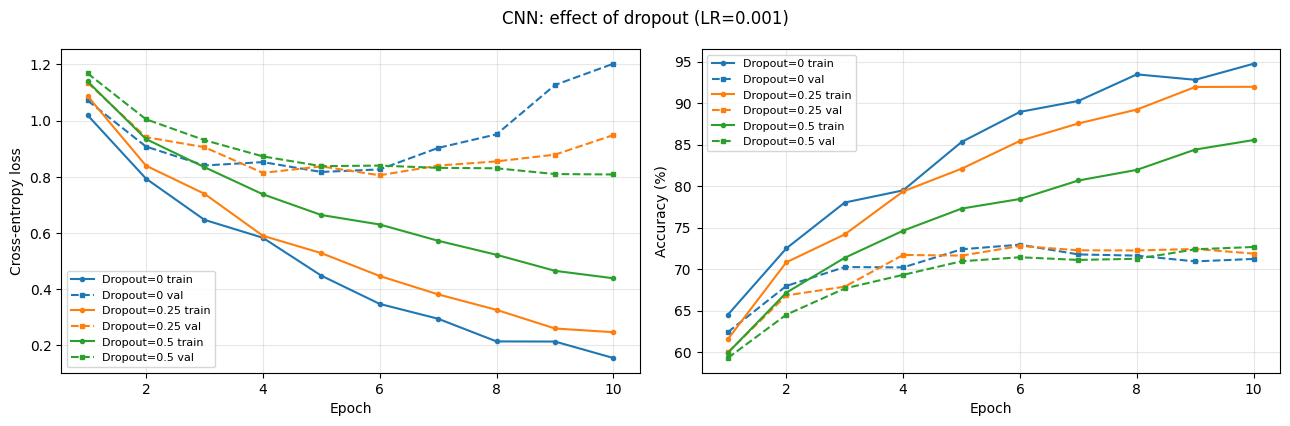

In [11]:
for m in ["MLP", "CNN"]:
    plot_runs([(f"Dropout={d:g}", get(m, BASE_LR, d)) for d in [0, 0.25, 0.5]],
              f"{m}: effect of dropout (LR=0.001)")

## 6. Results table

*Train and validation accuracy are from the last epoch. Test accuracy is from the epoch with the best validation accuracy. "Observation" is generated by comparing each run with the baseline of the same model, using the rules below.*

| Diagnosis rule | Condition (last epoch) |
|---|---|
| Underfitting | training accuracy below 50% |
| Clear overfitting | training minus validation accuracy above 10 points |
| Mild overfitting | gap between 5 and 10 points |
| Good fit | gap of 5 points or less |

Additionally, if the validation loss reached its minimum at least 2 epochs before the end and finished more than 5% above that minimum, the observation flags it as a classic overfitting signal.

In [12]:
def diagnose(r):
    gap = r["train_acc"] - r["val_acc"]
    vl = r["hist"]["val_loss"]
    k = int(np.argmin(vl))
    rising = (len(vl) - 1 - k) >= 2 and vl[-1] > 1.05 * vl[k]
    if r["train_acc"] < 50:
        level, text = "under", f"Underfitting: train accuracy only {r['train_acc']:.1f}%"
    elif gap > 10:
        level, text = "over", f"Clear overfitting: train minus val gap {gap:.1f} points"
    elif gap > 5:
        level, text = "mild", f"Mild overfitting: gap {gap:.1f} points"
    else:
        level, text = "fit", f"Good fit: gap {gap:.1f} points"
    if rising and level != "under":
        text += f"; val loss bottomed out at epoch {k + 1} and then rose"
    return level, text

def observe(r):
    level, text = diagnose(r)
    r["level"] = level
    if r["factor"] == "Baseline":
        return "Reference run. " + text + "."
    base = get(r["model"], BASE_LR, BASE_DROPOUT)
    delta = r["test_acc"] - base["test_acc"]
    value = f"{r['lr']:g}" if r["factor"] == "Learning rate" else f"{r['dropout']:g}"
    return (f"{r['factor']} = {value}: test accuracy {delta:+.1f} points vs baseline. "
            f"{text}. Best epoch {r['best_epoch']} of {EPOCHS}.")

rows = []
order = lambda r: (r["model"] != "MLP", r["factor"] != "Baseline", r["factor"], r["lr"], r["dropout"])
for r in sorted(results, key=order):
    rows.append({
        "Model / Configuration": r["label"],
        "Test Accuracy (%)": round(r["test_acc"], 2),
        "Parameters": f"{r['params']:,}",
        "Train Acc (%)": round(r["train_acc"], 1),
        "Val Acc (%)": round(r["val_acc"], 1),
        "Observation": observe(r),
    })
results_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 250)
display(results_df.style.set_properties(subset=["Observation"], **{"text-align": "left", "white-space": "normal"})
        .hide(axis="index"))

Model / Configuration,Test Accuracy (%),Parameters,Train Acc (%),Val Acc (%),Observation
"MLP, LR=0.001, Dropout=0 (baseline)",51.290000,"1,707,274",71.200000,51.700000,Reference run. Clear overfitting: train minus val gap 19.5 points; val loss bottomed out at epoch 5 and then rose.
"MLP, LR=0.001, Dropout=0.25",49.710000,"1,707,274",58.700000,49.900000,Dropout = 0.25: test accuracy -1.6 points vs baseline. Mild overfitting: gap 8.8 points. Best epoch 10 of 10.
"MLP, LR=0.001, Dropout=0.5",44.450000,"1,707,274",47.400000,44.400000,Dropout = 0.5: test accuracy -6.8 points vs baseline. Underfitting: train accuracy only 47.4%. Best epoch 10 of 10.
"MLP, LR=0.0001, Dropout=0",53.750000,"1,707,274",71.800000,53.000000,Learning rate = 0.0001: test accuracy +2.5 points vs baseline. Clear overfitting: train minus val gap 18.8 points. Best epoch 9 of 10.
"MLP, LR=0.01, Dropout=0",23.580000,"1,707,274",19.800000,18.300000,Learning rate = 0.01: test accuracy -27.7 points vs baseline. Underfitting: train accuracy only 19.8%. Best epoch 2 of 10.
"CNN, LR=0.001, Dropout=0 (baseline)",72.170000,"545,098",94.700000,71.200000,Reference run. Clear overfitting: train minus val gap 23.5 points; val loss bottomed out at epoch 5 and then rose.
"CNN, LR=0.001, Dropout=0.25",72.020000,"545,098",92.000000,71.900000,Dropout = 0.25: test accuracy -0.2 points vs baseline. Clear overfitting: train minus val gap 20.1 points; val loss bottomed out at epoch 6 and then rose. Best epoch 6 of 10.
"CNN, LR=0.001, Dropout=0.5",73.340000,"545,098",85.500000,72.700000,Dropout = 0.5: test accuracy +1.2 points vs baseline. Clear overfitting: train minus val gap 12.9 points. Best epoch 10 of 10.
"CNN, LR=0.0001, Dropout=0",65.440000,"545,098",69.900000,65.300000,Learning rate = 0.0001: test accuracy -6.7 points vs baseline. Good fit: gap 4.6 points. Best epoch 9 of 10.
"CNN, LR=0.01, Dropout=0",47.480000,"545,098",52.100000,48.300000,Learning rate = 0.01: test accuracy -24.7 points vs baseline. Good fit: gap 3.8 points. Best epoch 10 of 10.


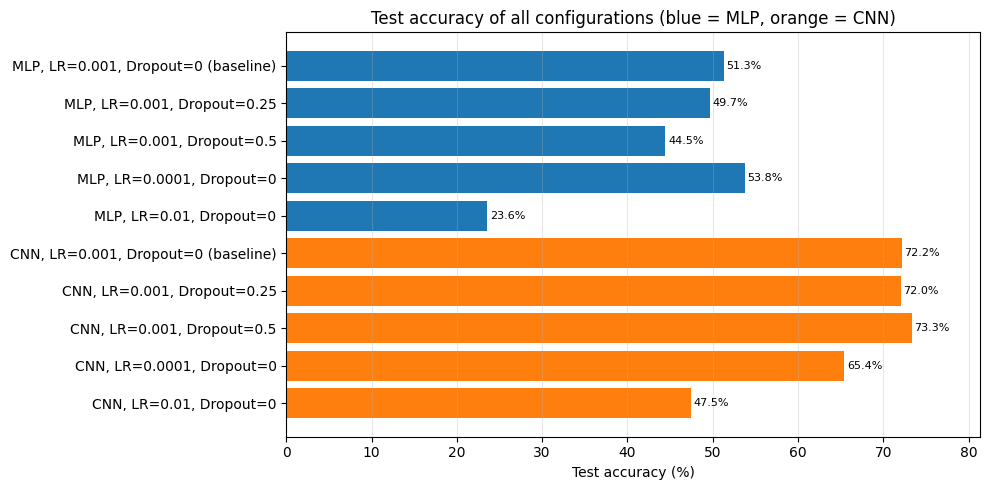

In [13]:
# One-glance summary of every configuration
ordered = sorted(results, key=order)[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["tab:blue" if r["model"] == "MLP" else "tab:orange" for r in ordered]
ax.barh([r["label"] for r in ordered], [r["test_acc"] for r in ordered], color=colors)
for y, r in enumerate(ordered):
    ax.text(r["test_acc"] + 0.3, y, f"{r['test_acc']:.1f}%", va="center", fontsize=8)
ax.set_xlabel("Test accuracy (%)"); ax.set_xlim(0, max(r["test_acc"] for r in ordered) + 8)
ax.set_title("Test accuracy of all configurations (blue = MLP, orange = CNN)")
ax.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.show()

## 7. Discussion

*The six points below are generated from the actual numbers above (so they always match the table), and they answer the questions in the task: which model is better, which change mattered most, whether complexity always helped, under/overfitting, and the recommended configuration.*

In [14]:
mlp_runs = [r for r in results if r["model"] == "MLP"]
cnn_runs = [r for r in results if r["model"] == "CNN"]
b_mlp, b_cnn = get("MLP", BASE_LR, BASE_DROPOUT), get("CNN", BASE_LR, BASE_DROPOUT)
best_mlp, best_cnn = max(mlp_runs, key=lambda r: r["test_acc"]), max(cnn_runs, key=lambda r: r["test_acc"])

# ---- 1. which model is better
cnn_wins = best_cnn["test_acc"] > best_mlp["test_acc"]
winner, loser = ("CNN", "MLP") if cnn_wins else ("MLP", "CNN")
l1 = (f"**Better model:** the {winner} won. Baselines: CNN {b_cnn['test_acc']:.1f}% vs MLP {b_mlp['test_acc']:.1f}% test accuracy; "
      f"best tuned runs: CNN {best_cnn['test_acc']:.1f}% vs MLP {best_mlp['test_acc']:.1f}%. ")
l1 += ("Convolution and weight sharing exploit local spatial structure that an MLP throws away when it flattens the image."
       if cnn_wins else
       "This is unexpected for images; with only 10 epochs and a small CNN the usual advantage did not show up.")

# ---- 2. largest effect
spreads = {}
for m in ["MLP", "CNN"]:
    for factor in ["Learning rate", "Dropout"]:
        grp = [get(m, BASE_LR, BASE_DROPOUT)] + [r for r in results if r["model"] == m and r["factor"] == factor]
        val = (lambda r: r["lr"]) if factor == "Learning rate" else (lambda r: r["dropout"])
        hi, lo = max(grp, key=lambda r: r["test_acc"]), min(grp, key=lambda r: r["test_acc"])
        spreads[(m, factor)] = (hi["test_acc"] - lo["test_acc"], val(hi), val(lo))
(top_m, top_f), (top_s, top_hi, top_lo) = max(spreads.items(), key=lambda kv: kv[1][0])
avg = {f: np.mean([spreads[(m, f)][0] for m in ["MLP", "CNN"]]) for f in ["Learning rate", "Dropout"]}
l2 = (f"**Largest effect:** {top_f.lower()} on the {top_m}, which moved test accuracy by {top_s:.1f} points "
      f"(best at {top_hi:g}, worst at {top_lo:g}). Averaged over both models, learning rate changed accuracy by "
      f"{avg['Learning rate']:.1f} points and dropout by {avg['Dropout']:.1f} points.")

# ---- 3. complexity
ratio = b_mlp["params"] / b_cnn["params"]
if cnn_wins and b_cnn["params"] < b_mlp["params"]:
    l3 = (f"**Complexity is not accuracy:** the CNN has {ratio:.1f}x fewer trainable parameters ({b_cnn['params']:,} vs {b_mlp['params']:,}) "
          f"yet is {best_cnn['test_acc'] - best_mlp['test_acc']:.1f} points better, so the right inductive bias beats raw size.")
elif cnn_wins:
    l3 = (f"**Complexity helped only when it was the right kind:** the CNN ({b_cnn['params']:,} parameters) beat the MLP ({b_mlp['params']:,}), "
          f"but its advantage comes from convolutional structure rather than parameter count alone.")
else:
    l3 = (f"**Complexity did not guarantee accuracy:** the MLP has {b_mlp['params']:,} parameters vs {b_cnn['params']:,} for the CNN, "
          f"and parameter count by itself does not explain the ranking.")
reg_helped = [m for m in ["MLP", "CNN"]
              if max(get(m, BASE_LR, d)["test_acc"] for d in [0.25, 0.5]) > get(m, BASE_LR, 0.0)["test_acc"]]
l3 += (f" Constraining capacity with dropout improved the {' and '.join(reg_helped)}." if reg_helped
       else " Constraining capacity with dropout did not improve test accuracy in this budget.")

# ---- 4. under / overfitting
over  = [r for r in results if r["level"] in ("over",)]
mild  = [r for r in results if r["level"] == "mild"]
under = [r for r in results if r["level"] == "under"]
gap = lambda r: r["train_acc"] - r["val_acc"]
parts = []
for m in ["MLP", "CNN"]:
    g0, g5 = gap(get(m, BASE_LR, 0.0)), gap(get(m, BASE_LR, 0.5))
    parts.append(f"{m} gap {g0:.1f} to {g5:.1f} points ({'narrowed' if g5 < g0 - 0.5 else ('widened' if g5 > g0 + 0.5 else 'barely changed')})")
l4 = (f"**Fit:** {len(over)} runs overfit clearly, {len(mild)} mildly, {len(under)} underfit, out of {len(results)}. "
      + (f"Worst overfit: {max(over, key=gap)['label']} (gap {gap(max(over, key=gap)):.1f} points). " if over else "")
      + (f"Underfit: {', '.join(r['label'] for r in under)}. " if under else "")
      + "Dropout 0 to 0.5 effect on the train/val gap: " + "; ".join(parts) + ".")

# ---- 5. recommendation
rec = max(results, key=lambda r: r["best_val_acc"])
l5 = (f"**Recommended configuration:** {rec['label']} (chosen by validation accuracy, {rec['best_val_acc']:.1f}%), "
      f"which reaches {rec['test_acc']:.1f}% test accuracy with {rec['params']:,} trainable parameters.")

# ---- 6. caveat
l6 = ("**Caveat:** every configuration was run once with seed 42 for a fixed 10 epochs, and a 10,000 image test set has roughly "
      "+/-0.5 points of sampling noise, so differences below about 1 point should be treated as suggestive, not conclusive.")

display(Markdown("\n\n".join(f"{i}. {l}" for i, l in enumerate([l1, l2, l3, l4, l5, l6], 1))))

1. **Better model:** the CNN won. Baselines: CNN 72.2% vs MLP 51.3% test accuracy; best tuned runs: CNN 73.3% vs MLP 53.8%. Convolution and weight sharing exploit local spatial structure that an MLP throws away when it flattens the image.

2. **Largest effect:** learning rate on the MLP, which moved test accuracy by 30.2 points (best at 0.0001, worst at 0.01). Averaged over both models, learning rate changed accuracy by 27.4 points and dropout by 4.1 points.

3. **Complexity is not accuracy:** the CNN has 3.1x fewer trainable parameters (545,098 vs 1,707,274) yet is 19.6 points better, so the right inductive bias beats raw size. Constraining capacity with dropout improved the CNN.

4. **Fit:** 5 runs overfit clearly, 1 mildly, 2 underfit, out of 10. Worst overfit: CNN, LR=0.001, Dropout=0 (baseline) (gap 23.5 points). Underfit: MLP, LR=0.01, Dropout=0, MLP, LR=0.001, Dropout=0.5. Dropout 0 to 0.5 effect on the train/val gap: MLP gap 19.5 to 3.0 points (narrowed); CNN gap 23.5 to 12.9 points (narrowed).

5. **Recommended configuration:** CNN, LR=0.001, Dropout=0 (baseline) (chosen by validation accuracy, 72.9%), which reaches 72.2% test accuracy with 545,098 trainable parameters.

6. **Caveat:** every configuration was run once with seed 42 for a fixed 10 epochs, and a 10,000 image test set has roughly +/-0.5 points of sampling noise, so differences below about 1 point should be treated as suggestive, not conclusive.

## 8. Per-experiment observations (summary)

The `Observation` column of the results table in Section 6 holds the observation for each individual experiment. The six points in Section 7 are the final discussion and conclusion.

**Limitations to keep in mind:** a single seed, a fixed 10 epoch budget, and one-factor-at-a-time changes (which cannot reveal interactions, for example a higher dropout rate that only pays off together with a larger model or longer training). A natural follow-up would be data augmentation and batch norm for the CNN, and averaging over 3 to 5 seeds.